## Linear delayed feedback — theory

Theory of linear delayed feedback control. 

Figures are saved to the project `figures/` directory and to `delayed_feedback_model/media/`.

In [7]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
from scipy.interpolate import interp1d
plt.rcParams['figure.max_open_warning'] = 0
import os
import sys
from pathlib import Path
from datetime import date
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import SPEED_ONSETS_DIR, FIGURES_DIR, notebook_media_dir
path = str(SPEED_ONSETS_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("delayed_feedback_model"))

%load_ext autoreload
%autoreload 2
from functions.feedback_models import *
from tqdm import tqdm
from scipy.special import lambertw
import matplotlib as mpl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
# path, path_media set in first cell

In [9]:
# path_media created in first cell

In [10]:
time=np.linspace(-1,10,1000)

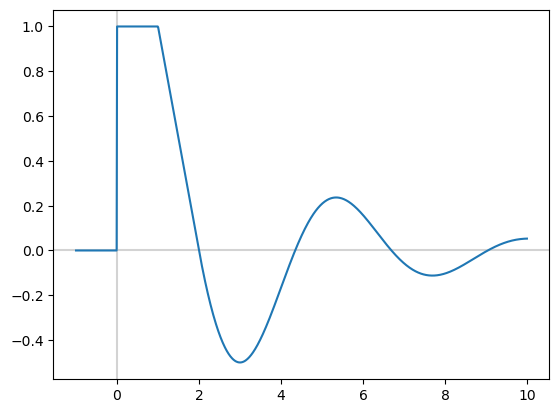

In [11]:
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.axvline(0,color='lightgray')
ax.plot(time,delay_unit_solution(time,k=1,tau=1))
plt.show()

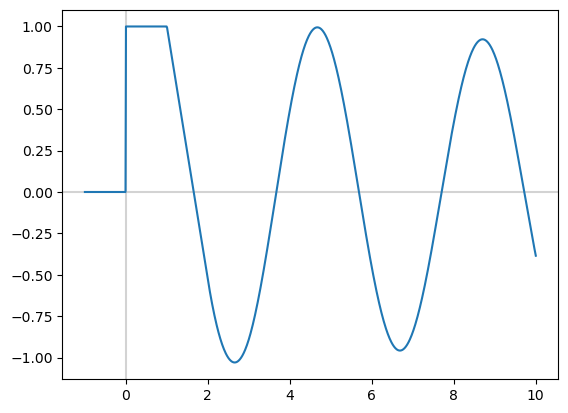

In [12]:
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.axvline(0,color='lightgray')
ax.plot(time,delay_unit_solution(time,k=1.53,tau=1))
plt.show()

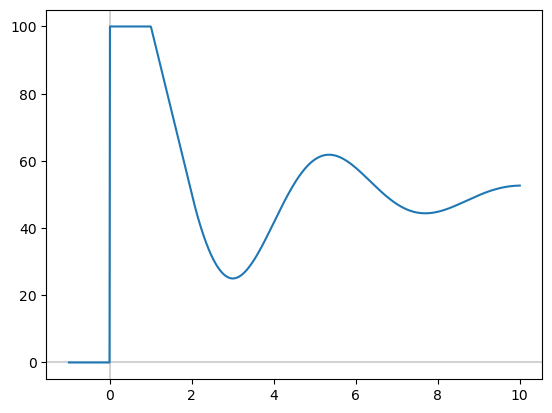

In [13]:
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.axvline(0,color='lightgray')
ax.plot(time,delay_rescaled_solution(time,vi=100,vt=50,k=1,tau=1))
plt.show()

#### Example plots:

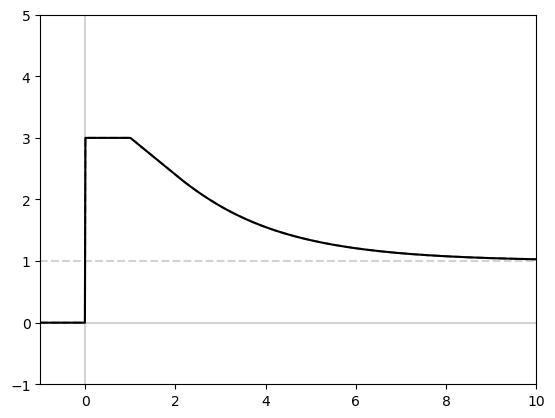

In [14]:
vi=3
vt=1
k=0.3
tau=1
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.axhline(vt,color='lightgray',ls='--')
ax.axvline(0,color='lightgray')
ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau,set_to_zero=False),'k--',alpha=0.5)
ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau),'k')
ax.set_xlim(time[0],time[-1])
ax.set_ylim(-1,5)
plt.show()

In [15]:
1/np.e,np.pi/2

(0.36787944117144233, 1.5707963267948966)

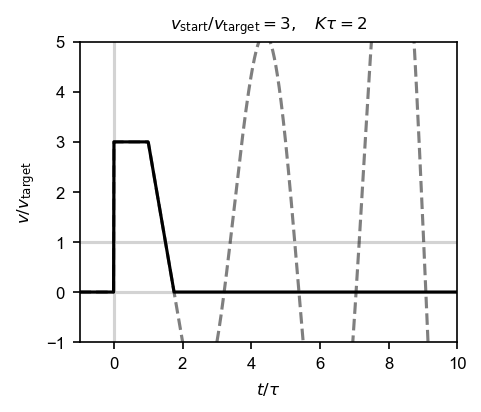

In [16]:
arial()
inline()

fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.5*textwidthSI,dpi=150)

vi=3
k=2
vt=1
tau=1

ax.axhline(0,color='lightgray')
ax.axhline(vt,color='lightgray')
ax.axvline(0,color='lightgray')
ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau,set_to_zero=False),'k--',alpha=0.5)
ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau),'k')
ax.set_xlim(time[0],time[-1])
ax.set_ylim(-1,5)

ax.set_xlabel(r'$t/\tau$')
ax.set_ylabel(r'$v/v_\mathrm{target}$')
ax.set_title(r'$v_\mathrm{start}/v_\mathrm{target}='+str(vi)+r',\quad K\tau='+str(k)+'$',size=8)

plt.show()

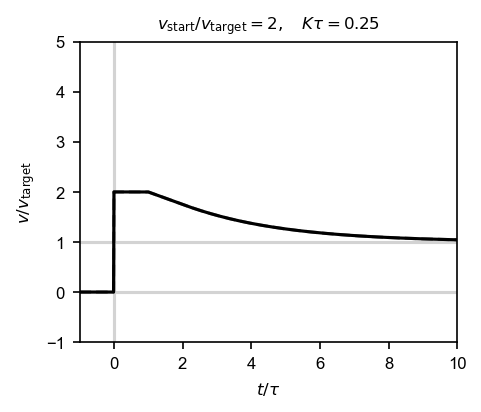

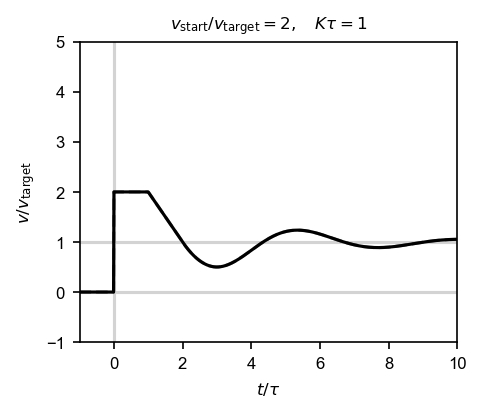

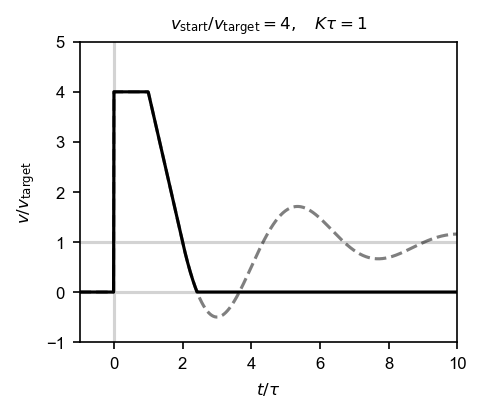

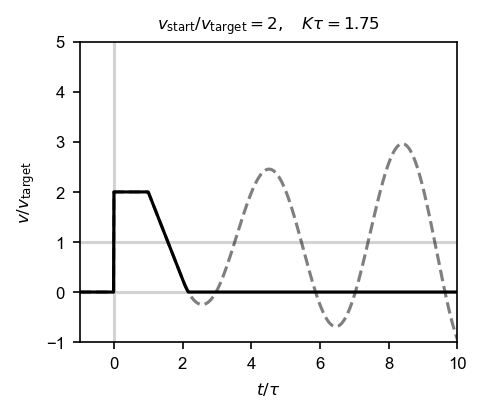

In [18]:
arial()
inline()

params=[[2,0.25],[2,1],[4,1],[2,1.75]]
vt=1
tau=1

for param in params:
    vi,k=param
    fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.5*textwidthSI,dpi=150)

    ax.axhline(0,color='lightgray')
    ax.axhline(vt,color='lightgray')
    ax.axvline(0,color='lightgray')
    ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau,set_to_zero=False),'k--',alpha=0.5)
    ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau),'k')
    ax.set_xlim(time[0],time[-1])
    ax.set_ylim(-1,5)
    
    ax.set_xlabel(r'$t/\tau$')
    ax.set_ylabel(r'$v/v_\mathrm{target}$')
    ax.set_title(r'$v_\mathrm{start}/v_\mathrm{target}='+str(vi)+r',\quad K\tau='+str(k)+'$',size=8)

    plt.show()

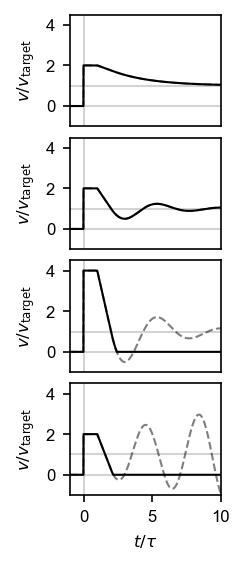

In [19]:
arial()
inline()
fig,axs=plt.subplots(4,1,figsize=np.array([1,3.2])*0.2*textwidthSI,dpi=150,sharex=True)
axs=axs.ravel()
plt.subplots_adjust(hspace=0.1,wspace=0.1)

params=[[2,0.25],[2,1],[4,1],[2,1.75]]
vt=1
tau=1
lw=1

for i,param in enumerate(params):
    ax=axs[i]
    vi,k=param

    ax.axhline(0,color='lightgray',lw=lw)
    ax.axhline(vt,color='lightgray',lw=lw)
    ax.axvline(0,color='lightgray',lw=lw)
    ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau,set_to_zero=False),'k--',alpha=0.5,lw=lw)
    ax.plot(time,delay_rescaled_solution(time,vi=vi,vt=vt,k=k,tau=tau),'k',lw=lw)
    ax.set_xlim(time[0],time[-1])
    ax.set_ylim(-1,4.5)



    if i==3:
        ax.set_xlabel(r'$t/\tau$')
    else:
        ax.tick_params(bottom=False)
        
    ax.set_ylabel(r'$v/v_\mathrm{target}$')

fig.align_labels()

plt.savefig(os.path.join(path_media,f'Fig_4c_example_speed_onset_traces.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_4c_example_speed_onset_traces.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

#### Minimum speed:

In [20]:
tt=np.linspace(0,30,1000)
gs=np.linspace(1/np.e,np.pi/2,100)
gs=gs[1:-1]
xmins=np.zeros(len(gs))
tmins=np.zeros(len(gs))
for i in range(len(gs)):
    ys=delay_unit_solution(tt,k=gs[i],tau=1)
    xmins[i]=np.min(ys)
    tmins[i]=tt[np.argmin(ys)]

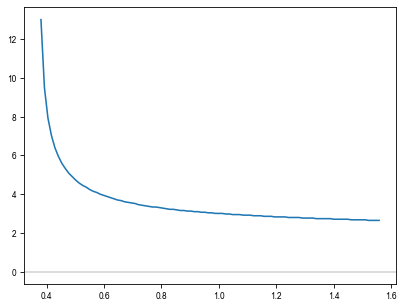

In [21]:
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=75)
ax.axhline(0,color='lightgray')
ax.plot(gs,tmins,'-')
plt.show()

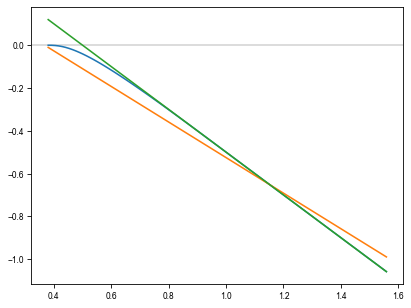

In [22]:
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=75)
ax.axhline(0,color='lightgray')
ax.plot(gs,xmins,'-')
ax.plot(gs,-(gs-1/np.e)/(np.pi/2-1/np.e),'-')
ax.plot(gs,0.5-gs,'-')
plt.show()

Whole range:

In [23]:
Npoints=300
tt=np.linspace(0,30,1000)
gs=np.linspace(0,2,Npoints)
xmins=np.zeros(len(gs))
tmins=np.zeros(len(gs))
xmaxs=np.zeros(len(gs))
tmaxs=np.zeros(len(gs))
for i in range(len(gs)):
    ys=delay_unit_solution(tt,k=gs[i],tau=1)
    xmins[i]=np.min(ys)
    tmins[i]=tt[np.argmin(ys)]
    xmaxs[i]=np.max(ys)
    tmaxs[i]=tt[np.argmax(ys)]
xmins[gs>np.pi/2]=np.nan
xmins[gs<1/np.e]=0
xmaxs[gs>np.pi/2]=np.nan

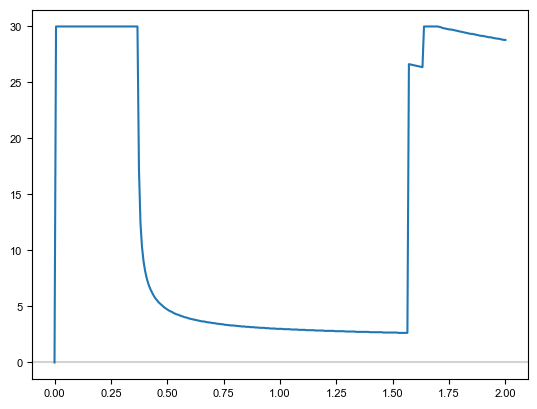

In [24]:
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.plot(gs,tmins,'-')
plt.show()

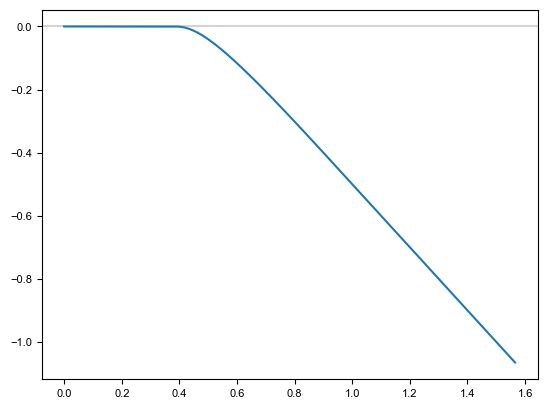

In [25]:
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.plot(gs,xmins,'-')
plt.show()

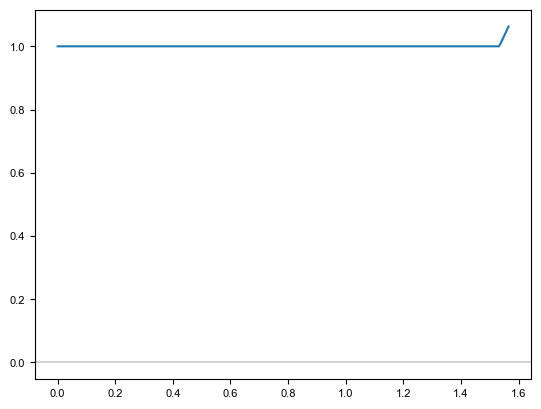

In [26]:
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.plot(gs,xmaxs,'-')
plt.show()

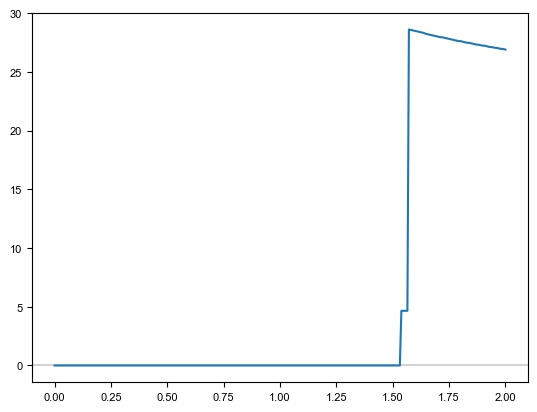

In [27]:
fig,ax=plt.subplots()
ax.axhline(0,color='lightgray')
ax.plot(gs,tmaxs,'-')
plt.show()

In [28]:
vt=1
vis=np.linspace(0,5,Npoints)
vmins=np.zeros((len(gs),len(vis)))
for i in range(len(gs)):
    for j in range(len(vis)):
        if vis[j]>1:
            vmins[i,j]=vt+(vis[j]-vt)*xmins[i]
        else:
            vmins[i,j]=vt+(vis[j]-vt)*xmaxs[i]

In [29]:
gs_b=get_linear_boundaries(gs)
vis_b=get_linear_boundaries(vis)

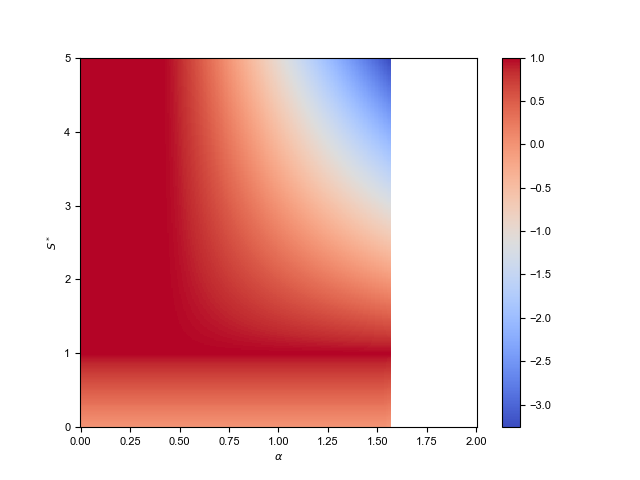

In [30]:
widget()
fig,ax=plt.subplots()
im=ax.pcolormesh(gs_b,vis_b,vmins.T,cmap='coolwarm',rasterized=True)
fig.colorbar(im,ax=ax)

ax.set_xlabel(r'$\alpha$')
ax.set_ylabel(r'$S^*$')

plt.show()

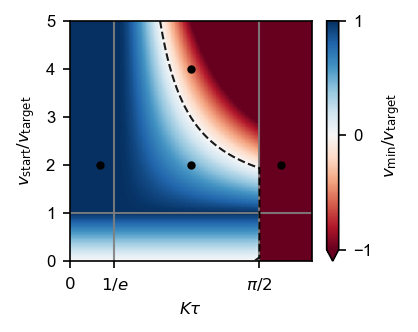

In [31]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.4*textwidthSI,dpi=150)
vmax=1
lw=1

cmap = mpl.colormaps['RdBu']
cmap.set_bad(color=cmap(0))

im=ax.pcolormesh(gs_b,vis_b,vmins.T,cmap=cmap,vmin=-vmax,vmax=vmax,rasterized=True)
cbar=fig.colorbar(im,ax=ax,extend='min')
cbar.set_label(r'$v_\mathrm{min}/v_\mathrm{target}$')
cbar.set_ticks([-1,0,1])
ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)

maskmin=(gs>1/np.e+0.1)&(gs<np.pi/2)
maskmax=(xmaxs>1)&(gs<np.pi/2)
gs_boundary=np.concatenate([gs[maskmin],[np.pi/2,np.pi/2],gs[maskmax][::-1],[gs[maskmax][0]]])
vis_boundary=np.concatenate([vt-vt/xmins[maskmin],[vt-vt/xmins[maskmin][-1],vt-vt/xmaxs[maskmax][-1]],vt-vt/xmaxs[maskmax][::-1],[0]])
ax.plot(gs_boundary,vis_boundary,color='k',alpha=alphalines,ls='--',lw=lw)

ax.plot([param[1] for param in params],[param[0] for param in params],'k.')

ax.set_xlim(gs_b[0],gs_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$K \tau$')
ax.set_ylabel(r'$v_\mathrm{start}/v_\mathrm{target}$')

plt.savefig(os.path.join(path_media,f'Fig_4b_phase_space_linear_model.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_4b_phase_space_linear_model.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

#### Analytical approximation:

In [32]:
vt=1
Npoints=300
gs=np.linspace(0,2,Npoints)
vis=np.linspace(0,5,Npoints)
vmins_approx=np.zeros((len(gs),len(vis)))
xmins_approx=np.zeros(len(gs))
for i in range(len(gs)):
    if gs[i]<0.5:
        xmins_approx[i]=0
    elif gs[i]>0.5 and gs[i]<np.pi/2:
        xmins_approx[i]=0.5-gs[i]
    elif gs[i]>np.pi/2:
        xmins_approx[i]=np.nan   
    for j in range(len(vis)):
        if vis[j]>vt:
            vmins_approx[i,j]=vt+(vis[j]-vt)*xmins_approx[i]
        else:
            vmins_approx[i,j]=vis[j]

In [33]:
gs_b=get_linear_boundaries(gs)
vis_b=get_linear_boundaries(vis)

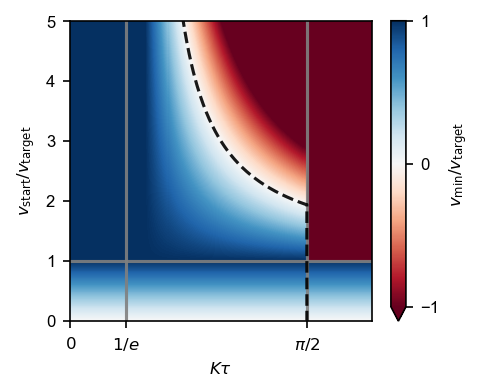

In [34]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.5*textwidthSI,dpi=150)
vmax=1

cmap = mpl.colormaps['RdBu']
cmap.set_bad(color=cmap(0))

im=ax.pcolormesh(gs_b,vis_b,vmins_approx.T,cmap=cmap,vmin=-vmax,vmax=vmax,rasterized=True)
cbar=fig.colorbar(im,ax=ax,extend='min')
cbar.set_label(r'$v_\mathrm{min}/v_\mathrm{target}$')
cbar.set_ticks([-1,0,1])
ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines)

mask=(gs>0.5)&(gs<np.pi/2)
gs_boundary=np.concatenate([gs[mask],[np.pi/2,np.pi/2]])
vis_boundary=np.concatenate([vt-vt/xmins_approx[mask],[vt-vt/xmins_approx[mask][-1],0]])
ax.plot(gs_boundary,vis_boundary,color='k',alpha=alphalines,ls='--')

ax.set_xlim(gs_b[0],gs_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$K \tau$')
ax.set_ylabel(r'$v_\mathrm{start}/v_\mathrm{target}$')

plt.show()

/var/folders/xl/ytwdm9h57dd5l_2fzzwzj7hw0000gn/T/ipykernel_13966/857064833.py:5: RuntimeWarning: invalid value encountered in divide
  im=ax.pcolormesh(gs_b,vis_b,(vmins_approx/vmins-1).T,cmap='RdBu',vmin=-vmax,vmax=vmax,rasterized=True)


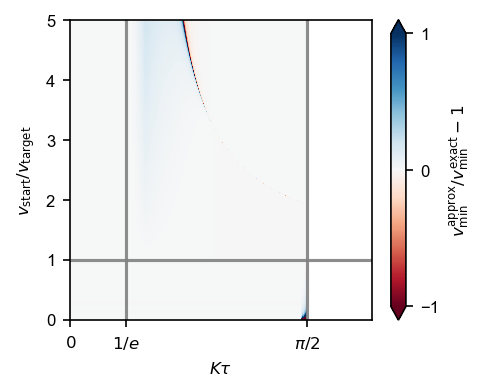

In [35]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.5*textwidthSI,dpi=150)
vmax=1
im=ax.pcolormesh(gs_b,vis_b,(vmins_approx/vmins-1).T,cmap='RdBu',vmin=-vmax,vmax=vmax,rasterized=True)
cbar=fig.colorbar(im,ax=ax,extend='both')
cbar.set_label(r'$v_\mathrm{min}^\mathrm{approx}/v_\mathrm{min}^\mathrm{exact}-1$')
cbar.set_ticks([-1,0,1])
ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines)

ax.set_xlim(gs_b[0],gs_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$K \tau$')
ax.set_ylabel(r'$v_\mathrm{start}/v_\mathrm{target}$')

plt.show()